In [1]:
# === Sanity import & device ===
import importlib, sys, torch, numpy as np
import matplotlib.pyplot as plt

import cwt_utils
importlib.reload(cwt_utils)

print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("cwt_utils loaded from:", cwt_utils.__file__)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE
if DEVICE: gpu = torch.cuda.get_device_name()
gpu

PyTorch: 2.5.1 | CUDA available: True
cwt_utils loaded from: c:\Deepfake\cwt_utils.py


'NVIDIA GeForce RTX 4090'

In [2]:
# === Test sintético: seno + chirp ===
from cwt_utils import CWT1D

def make_sine_series(T=64, fs=30.0, f0=1.2, amp=1.0):
    t = np.arange(T)/fs
    s = amp*np.sin(2*np.pi*f0*t).astype(np.float32)
    return s

def make_chirp_series(T=64, fs=30.0, f0=0.6, f1=2.0, amp=1.0):
    t = np.arange(T)/fs
    k = (f1 - f0) / (T/fs)   # sweep rate (Hz/s)
    phase = 2*np.pi*(f0*t + 0.5*k*t**2)
    s = amp*np.sin(phase).astype(np.float32)
    return s

# Construimos stack [T,1,H,W] con un único "píxel" (H=W=1)
fs = 30.0
T  = 64
sine = make_sine_series(T=T, fs=fs, f0=1.2)
chirp = make_chirp_series(T=T, fs=fs, f0=0.6, f1=2.0)

def to_tchw(x1d):
    x = x1d[:, None, None]           # [T,1,1]
    x = x.astype(np.float32)
    x = x[:, None, :, :]             # [T,1,1,1]
    return x

x_sine  = to_tchw(sine)
x_chirp = to_tchw(chirp)

# CWT (ROI) directo sobre cada señal
from cwt_utils import cwt_over_roi

cwt_cfg = dict(kernel_size=129, w0=6.5, n_bands=24, fmin=0.4, fmax=12.0)
W_sine,  freqs = cwt_over_roi(x_sine,  fps=fs, cwt_cfg=cwt_cfg)
W_chirp, _     = cwt_over_roi(x_chirp, fps=fs, cwt_cfg=cwt_cfg)

print("W_sine:",  W_sine.shape, "freqs:", freqs.shape)
print("W_chirp:", W_chirp.shape)

# Verificación 1: la banda de mayor energía en el seno cae cerca de f0
k_peak = np.argmax(W_sine.mean(axis=1))
f_hat  = float(freqs[k_peak])
print(f"[SINE] f0=1.2 Hz  | f_hat≈{f_hat:.3f} Hz  | Δf={abs(f_hat-1.2):.3f} Hz")
assert abs(f_hat-1.2) < 0.4, "El pico de frecuencia estimado está demasiado lejos (tolerancia 0.4 Hz)."

# Verificación 2: el chirp debe mostrar cresta creciente
ridge_idx = np.argmax(W_chirp, axis=0)   # [T]
is_increasing = ridge_idx[-1] > ridge_idx[0]
print(f"[CHIRP] cresta creciente: {is_increasing} (idx0={ridge_idx[0]}, idxT={ridge_idx[-1]})")
assert is_increasing, "La cresta del chirp no parece aumentar."


W_sine: (24, 64) freqs: (24,)
W_chirp: (24, 64)
[SINE] f0=1.2 Hz  | f_hat≈1.126 Hz  | Δf=0.074 Hz
[CHIRP] cresta creciente: True (idx0=7, idxT=9)


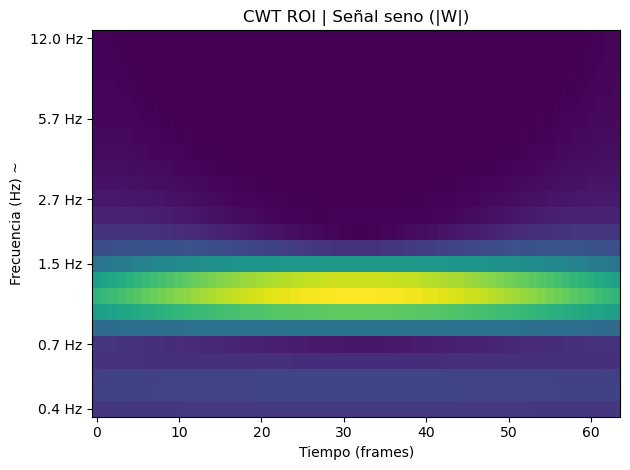

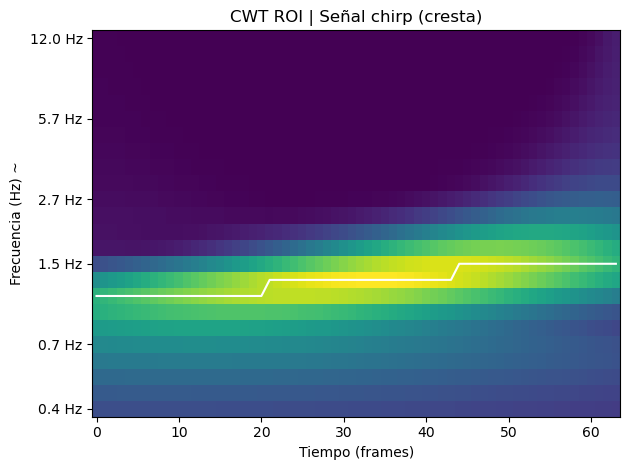

In [3]:
from cwt_utils import plot_roi_spectrogram, plot_chirp_ridge

plot_roi_spectrogram(W_sine,  freqs, title="CWT ROI | Señal seno (|W|)")
plot_chirp_ridge(W_chirp, freqs, title="CWT ROI | Señal chirp (cresta)")


ROI: (16, 48) | freqs[0:5]= [0.5  0.62 0.76 0.94 1.17]
GRID maps: (16, 48, 12, 12) (S,T,Gh,Gw)


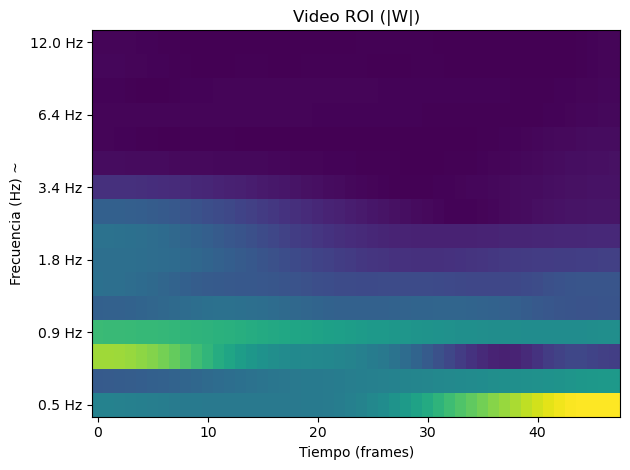

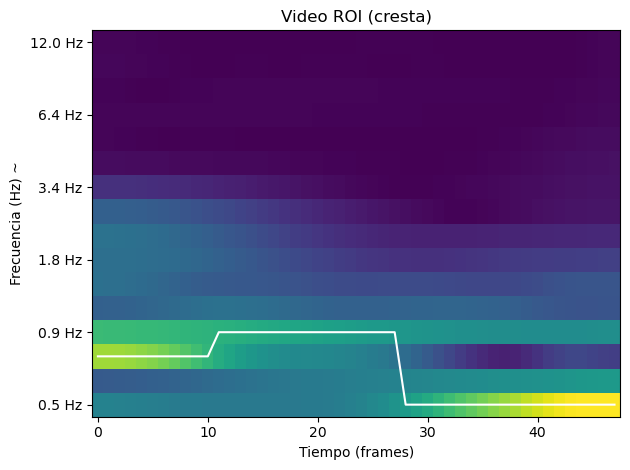

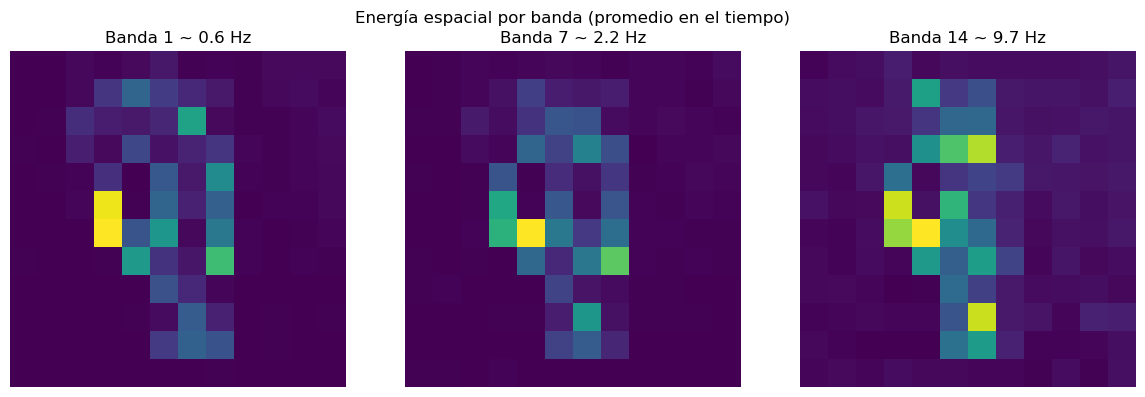

In [6]:
# === Video quick smoke test (ROI + GRID) ===
from cwt_utils import load_video_frames, to_grayscale, detrend_per_pixel, \
                       cwt_over_roi, cwt_per_pixel_downsample, plot_band_maps

VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\real\01__exit_phone_room.mp4"  # cambia si quieres

frames_rgb, fps_eff = load_video_frames(
    VIDEO_PATH, target_fps=30.0, max_frames=48, resize=(192,192)
)
x = to_grayscale(frames_rgb)
x = detrend_per_pixel(x)

# ROI
W_roi, freqs = cwt_over_roi(x, fps=fps_eff, cwt_cfg=dict(kernel_size=95, w0=6.5, n_bands=16, fmin=0.5, fmax=12.0))
print("ROI:", W_roi.shape, "| freqs[0:5]=", np.round(freqs[:5], 2))

# GRID (rápido)
W_maps, _ = cwt_per_pixel_downsample(x, fps=fps_eff, grid=(12,12), cwt_cfg=dict(kernel_size=95, w0=6.5, n_bands=16, fmin=0.5, fmax=12.0))
print("GRID maps:", W_maps.shape, "(S,T,Gh,Gw)")

# Plots
plot_roi_spectrogram(W_roi, freqs, title="Video ROI (|W|)")
plot_chirp_ridge(W_roi, freqs, title="Video ROI (cresta)")
sel = np.linspace(1, len(freqs)-2, num=min(3, len(freqs)-2), dtype=int).tolist()
plot_band_maps(W_maps, freqs, band_indices=sel)


DENSE maps: (12, 32, 96, 96) (S,T,H,W)


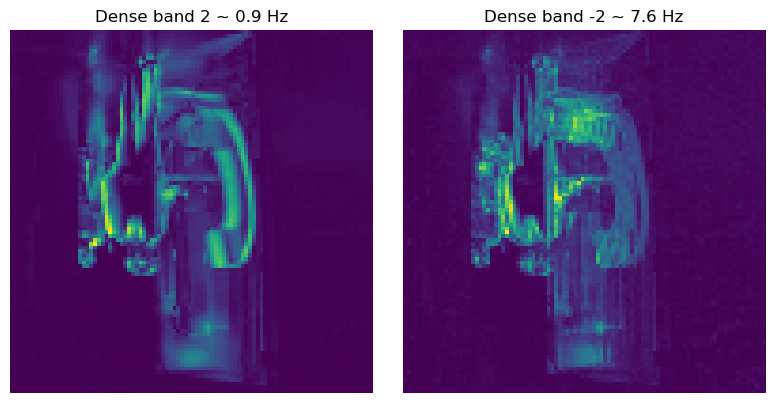

In [7]:
# === Pixelwise denso (cada píxel) con seguridad de VRAM ===
from cwt_utils import cwt_per_pixel_dense

# para evitar explotar memoria, usamos un clip pequeño
frames_rgb_small, fps_small = load_video_frames(
    VIDEO_PATH, target_fps=30.0, max_frames=32, resize=(96,96)
)
x_small = detrend_per_pixel(to_grayscale(frames_rgb_small))

W_full, freqs_d = cwt_per_pixel_dense(
    x_small, fps=fps_small, batch_size=1024,
    cwt_cfg=dict(kernel_size=95, w0=6.5, n_bands=12, fmin=0.5, fmax=10.0)
)
print("DENSE maps:", W_full.shape, "(S,T,H,W)")

# Visual: energía por banda promedio temporal para 2 bandas
E = W_full.mean(axis=1)  # [S,H,W]
plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.imshow(E[2], origin='lower'); plt.title(f"Dense band 2 ~ {freqs_d[2]:.1f} Hz"); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(E[-2], origin='lower'); plt.title(f"Dense band -2 ~ {freqs_d[-2]:.1f} Hz"); plt.axis('off')
plt.tight_layout(); plt.show()


In [8]:
# === Convertir CWT GRID a tokens de entrada (ej. TimeSformer) ===
import torch
from cwt_utils import CWTtoTokens

# tomamos el W_maps de la Celda 4 (GRID): [S,T,Gh,Gw]
W_maps_t = torch.from_numpy(W_maps).unsqueeze(0).to(torch.float32)  # [1,S,T,Gh,Gw]

tok = CWTtoTokens(S=W_maps_t.shape[1], patch=1, reduce_channels=64, embed_dim=256)
tokens = tok(W_maps_t)  # [1,T,Np,256]
print("Tokens shape:", tokens.shape)  # esperado: [1, T, Gh*Gw, 256]


Tokens shape: torch.Size([1, 48, 144, 256])


In [9]:
# === Import / reload / device ===
import importlib, torch, numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn

import diff_utils as DU
importlib.reload(DU)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())


PyTorch: 2.5.1 | CUDA: True


In [10]:
# === Schedule (cosine) ===
T = 300
sched = DU.build_schedule(T, device=DEVICE)  # cosine (Nichol&Dhariwal)

for k in ("betas","alphas","abar"):
    ten = sched[k]
    print(k, ten.shape, "min=%.3e max=%.3e" % (ten.min().item(), ten.max().item()))

# Verifica monotonicidad esperada
assert torch.all(sched["alphas"] > 0)
assert torch.all(sched["abar"][1:] <= sched["abar"][:-1] + 1e-7)  # abar debe decrecer o mantenerse
print("Schedule OK.")


betas torch.Size([300]) min=1.565e-04 max=9.990e-01
alphas torch.Size([300]) min=1.000e-03 max=9.998e-01
abar torch.Size([300]) min=2.699e-08 max=9.998e-01
Schedule OK.


In [11]:
# === Forward diffusion y reconstrucción x0 ===
B, C, H, W = 4, 1, 64, 64
x0 = torch.randn(B, C, H, W, device=DEVICE)

# Toma t aleatorio y muestrea x_t
t = torch.randint(1, T+1, (B,), device=DEVICE)
xt, eps_true = DU.sample_xt(x0, t, sched)

# Reconstrucción teórica de x0 (DDPM)
abar_t = sched["abar"][t-1].view(B,1,1,1)
x0_hat = (xt - torch.sqrt(1.0 - abar_t) * eps_true) / torch.sqrt(abar_t)

mse = (x0_hat - x0).pow(2).mean().item()
print(f"Recon x0 MSE ~ {mse:.3e} (debería ser ~0 dentro de precisión numérica)")
assert mse < 1e-6, "Reconstrucción de x0 inesperadamente alta."


Recon x0 MSE ~ 7.728e-15 (debería ser ~0 dentro de precisión numérica)


In [12]:
# === Un paso de entrenamiento (ε-MSE) + ELBO_est ===
model = DU.TinyUNet(in_ch=1, base=32, t_dim=128).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=2e-4)

ds = DU.ToyDataset(n=512, size=64)  # pequeño para smoke
dl = torch.utils.data.DataLoader(ds, batch_size=32, shuffle=True, drop_last=True)

x0_batch = next(iter(dl)).to(DEVICE)
loss_simple, elbo_est = DU.train_step(model, x0_batch, sched, opt)

print("loss_simple:", float(loss_simple), "| ELBO_est (↓ mejor):", float(elbo_est))


loss_simple: 1.0399754047393799 | ELBO_est (↓ mejor): 0.021582163870334625


== ELBO (batch) ==
ELBO_sum (↓ mejor): {'mean': 498.2507629394531, 'std': 11.25709342956543, 'min': 470.7104187011719, 'max': 519.3176879882812}
LT_sum: {'mean': 4.3911722968914546e-07, 'std': 1.2533914173218363e-07, 'min': 2.5367205580550944e-07, 'max': 6.913099923622212e-07}
KL_sum: {'mean': 502.1156005859375, 'std': 11.253898620605469, 'min': 474.5916748046875, 'max': 523.181884765625}
L0_sum: {'mean': -3.864847183227539, 'std': 0.012370212934911251, 'min': -3.88983154296875, 'max': -3.8405866622924805}


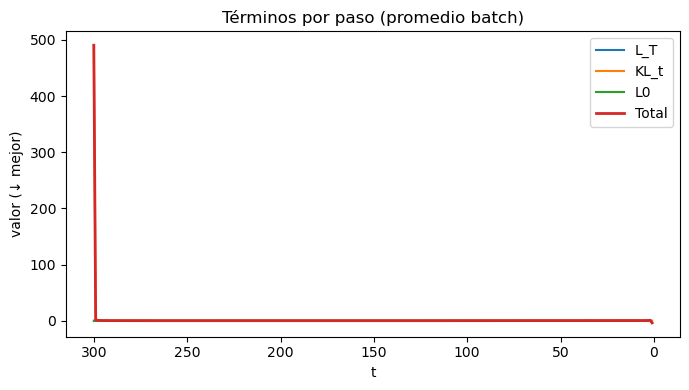

In [13]:
# === ELBO por paso (curvas) y acumulado ===
with torch.no_grad():
    steps = DU.elbo_per_timestep(model, x0_batch, T=T, sched=sched, t_order="desc")
    acc = DU.accumulate_per_timestep(steps)
    DU.print_summary(acc, "ELBO (batch)")

# Plot rápido per-step (promedio batch)
ts = [s.t for s in steps]
LT = torch.stack([s.LT.mean()   for s in steps]).cpu().numpy()
KL = torch.stack([s.KL_t.mean() for s in steps]).cpu().numpy()
L0 = torch.stack([s.L0.mean()   for s in steps]).cpu().numpy()
TOT= torch.stack([s.total.mean() for s in steps]).cpu().numpy()

plt.figure(figsize=(7,4))
plt.plot(ts, LT, label="L_T")
plt.plot(ts, KL, label="KL_t")
plt.plot(ts, L0, label="L0")
plt.plot(ts, TOT, label="Total", linewidth=2)
plt.gca().invert_xaxis()
plt.xlabel("t"); plt.ylabel("valor (↓ mejor)"); plt.title("Términos por paso (promedio batch)")
plt.legend(); plt.tight_layout(); plt.show()


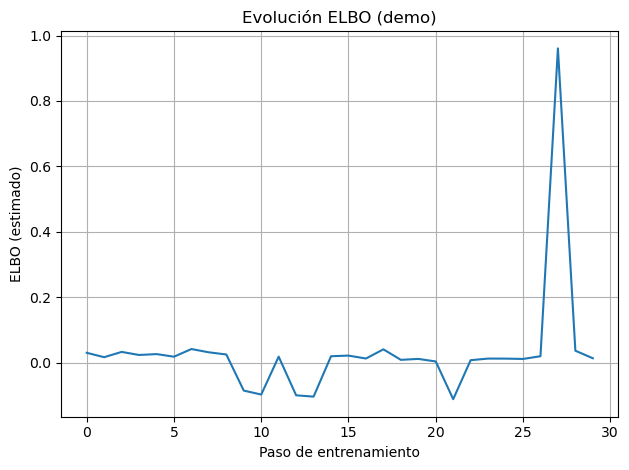

Último step — loss_simple=0.2010 | ELBO_est=0.0130


In [14]:
# === Mini loop de entrenamiento y curva ELBO ===
elbo_curve = []
epochs, steps_per_epoch = 1, 30
dl_iter = iter(dl)

model.train()
for _ in range(epochs * steps_per_epoch):
    try:
        x0_batch = next(dl_iter).to(DEVICE)
    except StopIteration:
        dl_iter = iter(dl)
        x0_batch = next(dl_iter).to(DEVICE)
    loss_simple, elbo_est = DU.train_step(model, x0_batch, sched, opt)
    elbo_curve.append(float(elbo_est))

DU.plot_elbo_curve(elbo_curve, title="Evolución ELBO (demo)")
print("Último step — loss_simple=%.4f | ELBO_est=%.4f" % (float(loss_simple), float(elbo_est)))


In [15]:
# === Comparación A (sin entrenar) vs B (afinando 20 pasos) ===
# Clona modelo "A" sin entrenar
model_A = DU.TinyUNet(in_ch=1, base=32, t_dim=128).to(DEVICE)
model_B = DU.TinyUNet(in_ch=1, base=32, t_dim=128).to(DEVICE)
model_B.load_state_dict(model_A.state_dict())  # mismo inicio

optB = torch.optim.AdamW(model_B.parameters(), lr=2e-4)

# Afinamos B unos pasos
for _ in range(20):
    try:
        x0_batch = next(dl_iter).to(DEVICE)
    except StopIteration:
        dl_iter = iter(dl)
        x0_batch = next(dl_iter).to(DEVICE)
    DU.train_step(model_B, x0_batch, sched, optB)

# Evaluamos ELBO acumulado por paso en el MISMO batch
x_eval = next(iter(dl)).to(DEVICE)
with torch.no_grad():
    steps_A = DU.elbo_per_timestep(model_A, x_eval, T=T, sched=sched, t_order="desc")
    acc_A = DU.accumulate_per_timestep(steps_A)

    steps_B = DU.elbo_per_timestep(model_B, x_eval, T=T, sched=sched, t_order="desc")
    acc_B = DU.accumulate_per_timestep(steps_B)

print("ELBO_sum mean — A: %.4f | B: %.4f (↓ mejor)" % (acc_A.elbo_sum.mean().item(), acc_B.elbo_sum.mean().item()))
gain = (acc_A.elbo_sum - acc_B.elbo_sum).mean().item()
print("Mejora promedio (A - B) =", gain)


ELBO_sum mean — A: 521.0708 | B: 72.4013 (↓ mejor)
Mejora promedio (A - B) = 448.66961669921875


In [16]:
# === Consistencia ddpm_mean_theta vs posterior ===
with torch.no_grad():
    x0 = next(iter(dl)).to(DEVICE)
    B = x0.size(0)
    t = torch.randint(2, T+1, (B,), device=DEVICE)  # t>1 para evaluar KL_t

    xt, eps_true = DU.sample_xt(x0, t, sched)
    # Modelo dummy: predice el epsilon verdadero (caso ideal)
    class Oracle(nn.Module):
        def forward(self, x, t_idx): return eps_true
    oracle = Oracle().to(DEVICE)

    eps_hat = oracle(xt, t)
    # Posterior y modelo
    LT, KL_t, L0 = DU.compute_vlb_terms(x0, eps_hat, xt, t, sched)

print("Con eps_hat = eps_true (oráculo) — KL_t mean: %.3e (≈0)" % KL_t.mean().item())


Con eps_hat = eps_true (oráculo) — KL_t mean: 2.508e-08 (≈0)


In [48]:
import importlib, train_utils, inspect
importlib.reload(train_utils)  # fuerza a leer el archivo guardado
print("Firma tras reload:", inspect.signature(train_utils.train_eps_unet_on_dfdc))


Firma tras reload: (root: str, outdir: str = './checkpoints_dfdc_eps', parts: Sequence[int] = (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49), image_size: int = 64, channels: int = 1, T: int = 300, batch_size: int = 64, steps_per_epoch: int = 1000, epochs: int = 2, lr: float = 0.0002, weight_decay: float = 0.01, samples_per_video: int = 2, max_videos: Optional[int] = None, seed: int = 0, use_face_crop: bool = False, resume_from: Optional[str] = None, resume_optimizer: bool = True, amp: bool = True, grad_clip: Optional[float] = 1.0, warmup_steps: int = 0) -> Dict[str, str]


c:\Users\labdsp\miniconda3\envs\Deepfake\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Epoch 1/5:  20% 157/800 [58:27<3:59:26, 22.34s/it, elbo=0.0311, loss=0.6863, lr=3.14e-05] 


[Epoch 1] loss=0.6863 | ELBO_est=0.0311 | saved: checkpoints_dfdc_eps\eps_unet_epoch1.pt


Epoch 2/5:  20% 157/800 [1:04:39<4:24:49, 24.71s/it, elbo=0.0162, loss=0.1410, lr=6.28e-05] 


[Epoch 2] loss=0.1410 | ELBO_est=0.0162 | saved: checkpoints_dfdc_eps\eps_unet_epoch2.pt


Epoch 3/5:  20% 157/800 [19:56<1:21:42,  7.62s/it, elbo=0.3644, loss=0.0981, lr=9.42e-05] 


[Epoch 3] loss=0.0981 | ELBO_est=0.3644 | saved: checkpoints_dfdc_eps\eps_unet_epoch3.pt


Epoch 4/5:  20% 157/800 [20:05<1:22:19,  7.68s/it, elbo=0.0081, loss=0.0895, lr=1.26e-04] 


[Epoch 4] loss=0.0895 | ELBO_est=0.0081 | saved: checkpoints_dfdc_eps\eps_unet_epoch4.pt


Epoch 5/5:  20% 157/800 [20:09<1:22:34,  7.71s/it, elbo=0.0020, loss=0.0654, lr=1.57e-04] 


[Epoch 5] loss=0.0654 | ELBO_est=0.0020 | saved: checkpoints_dfdc_eps\eps_unet_epoch5.pt
Log guardado en: checkpoints_dfdc_eps\training_log.csv
Checkpoint final: checkpoints_dfdc_eps\eps_unet_final.pt
Gráfico de entrenamiento guardado en: checkpoints_dfdc_eps\training_progress.png
{'csv': 'checkpoints_dfdc_eps\\training_log.csv', 'ckpt': 'checkpoints_dfdc_eps\\eps_unet_final.pt'}


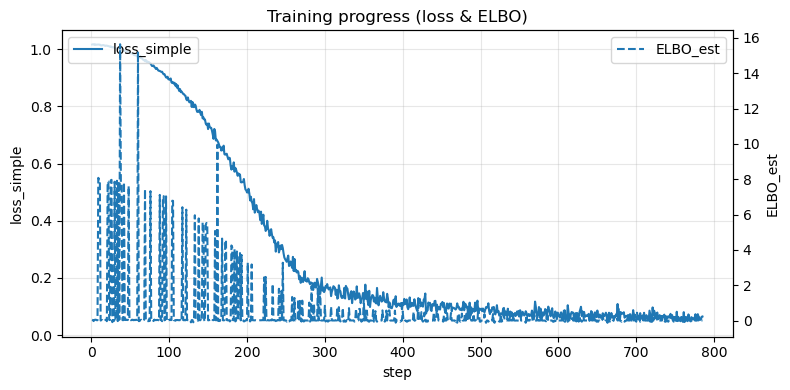

In [60]:
ROOT = r"E:\ERIS\Ernesto\dfdc_train_all"  # carpeta que contiene dfdc_train_part_0..49

res = train_utils.train_eps_unet_on_dfdc(
    root=ROOT,
    outdir="./checkpoints_dfdc_eps",
    parts=tuple(range(0, 10)),
    image_size=128,
    channels=3,
    T=300,
    batch_size=64,
    steps_per_epoch=800,
    epochs=5,
    lr=2e-4,
    weight_decay=0.25e-4,
    samples_per_video=4,
    max_videos=20000,
    use_face_crop=True,
    #amp=True,           # activa AMP si tienes CUDA
    grad_clip=1.0,      # clipping L2
    warmup_steps=1000,  # calentamiento de LR
    #resume_from="checkpoints_dfdc_eps/eps_unet_epoch8.pt",
    #resume_optimizer=True,
)
print(res)


In [61]:
# Debug rápido en tu notebook
import torch, numpy as np
from train_utils import make_dataloader
import diff_utils as DU

ROOT = r"E:\ERIS\Ernesto\dfdc_train_all"
dl = make_dataloader(ROOT, parts=tuple(range(0, 2)), batch_size=64,
                     samples_per_video=4, out_size=64, to_gray=True,
                     max_videos=256, face_crop_fn=None)  # desactiva face crop para aislar

x0 = next(iter(dl))
print("x0 stats:", x0.min().item(), x0.max().item(), torch.isnan(x0).any().item(), torch.isinf(x0).any().item())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
x0 = x0.to(device)
model = DU.TinyUNet(in_ch=1, base=32, t_dim=128).to(device).float()
sched = DU.build_schedule(T=300, device=device)

loss_simple, elbo_est = DU.train_step(model, x0, sched, torch.optim.AdamW(model.parameters(), lr=2e-4))
print("loss_simple=", float(loss_simple), "elbo_est=", float(elbo_est))


x0 stats: -0.9944172501564026 0.9997999668121338 False False
loss_simple= 1.0069174766540527 elbo_est= 0.03740237280726433


C:\Users\labdsp\AppData\Local\Temp\ipykernel_5548\3863650453.py:34: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(CKPT, map_location=DEVICE)


nymodlmxni.mp4                  ELBO_est =   0.0008   Tag = "REAL"  (crop -> ./probe_crops\nymodlmxni.mp4_frame0_crop.png)
lokzwdldxp.mp4                  ELBO_est =   0.0014   Tag = "REAL"  (crop -> ./probe_crops\lokzwdldxp.mp4_frame0_crop.png)
hntguogkqd.mp4                  ELBO_est =   0.0032   Tag = "REAL"  (crop -> ./probe_crops\hntguogkqd.mp4_frame0_crop.png)
objgwnmscm.mp4                  ELBO_est =   0.0008   Tag = "REAL"  (crop -> ./probe_crops\objgwnmscm.mp4_frame0_crop.png)
qyefejorlb.mp4                  ELBO_est =   0.0015   Tag = "REAL"  (crop -> ./probe_crops\qyefejorlb.mp4_frame0_crop.png)
gylcfcozce.mp4                  ELBO_est =   0.0071   Tag = "REAL"  (crop -> ./probe_crops\gylcfcozce.mp4_frame0_crop.png)
fpevfidstw.mp4                  ELBO_est =   0.0010   Tag = "REAL"  (crop -> ./probe_crops\fpevfidstw.mp4_frame0_crop.png)
upmgtackuf.mp4                  ELBO_est =   0.0031   Tag = "REAL"  (crop -> ./probe_crops\upmgtackuf.mp4_frame0_crop.png)
ucthmsajay.mp4  

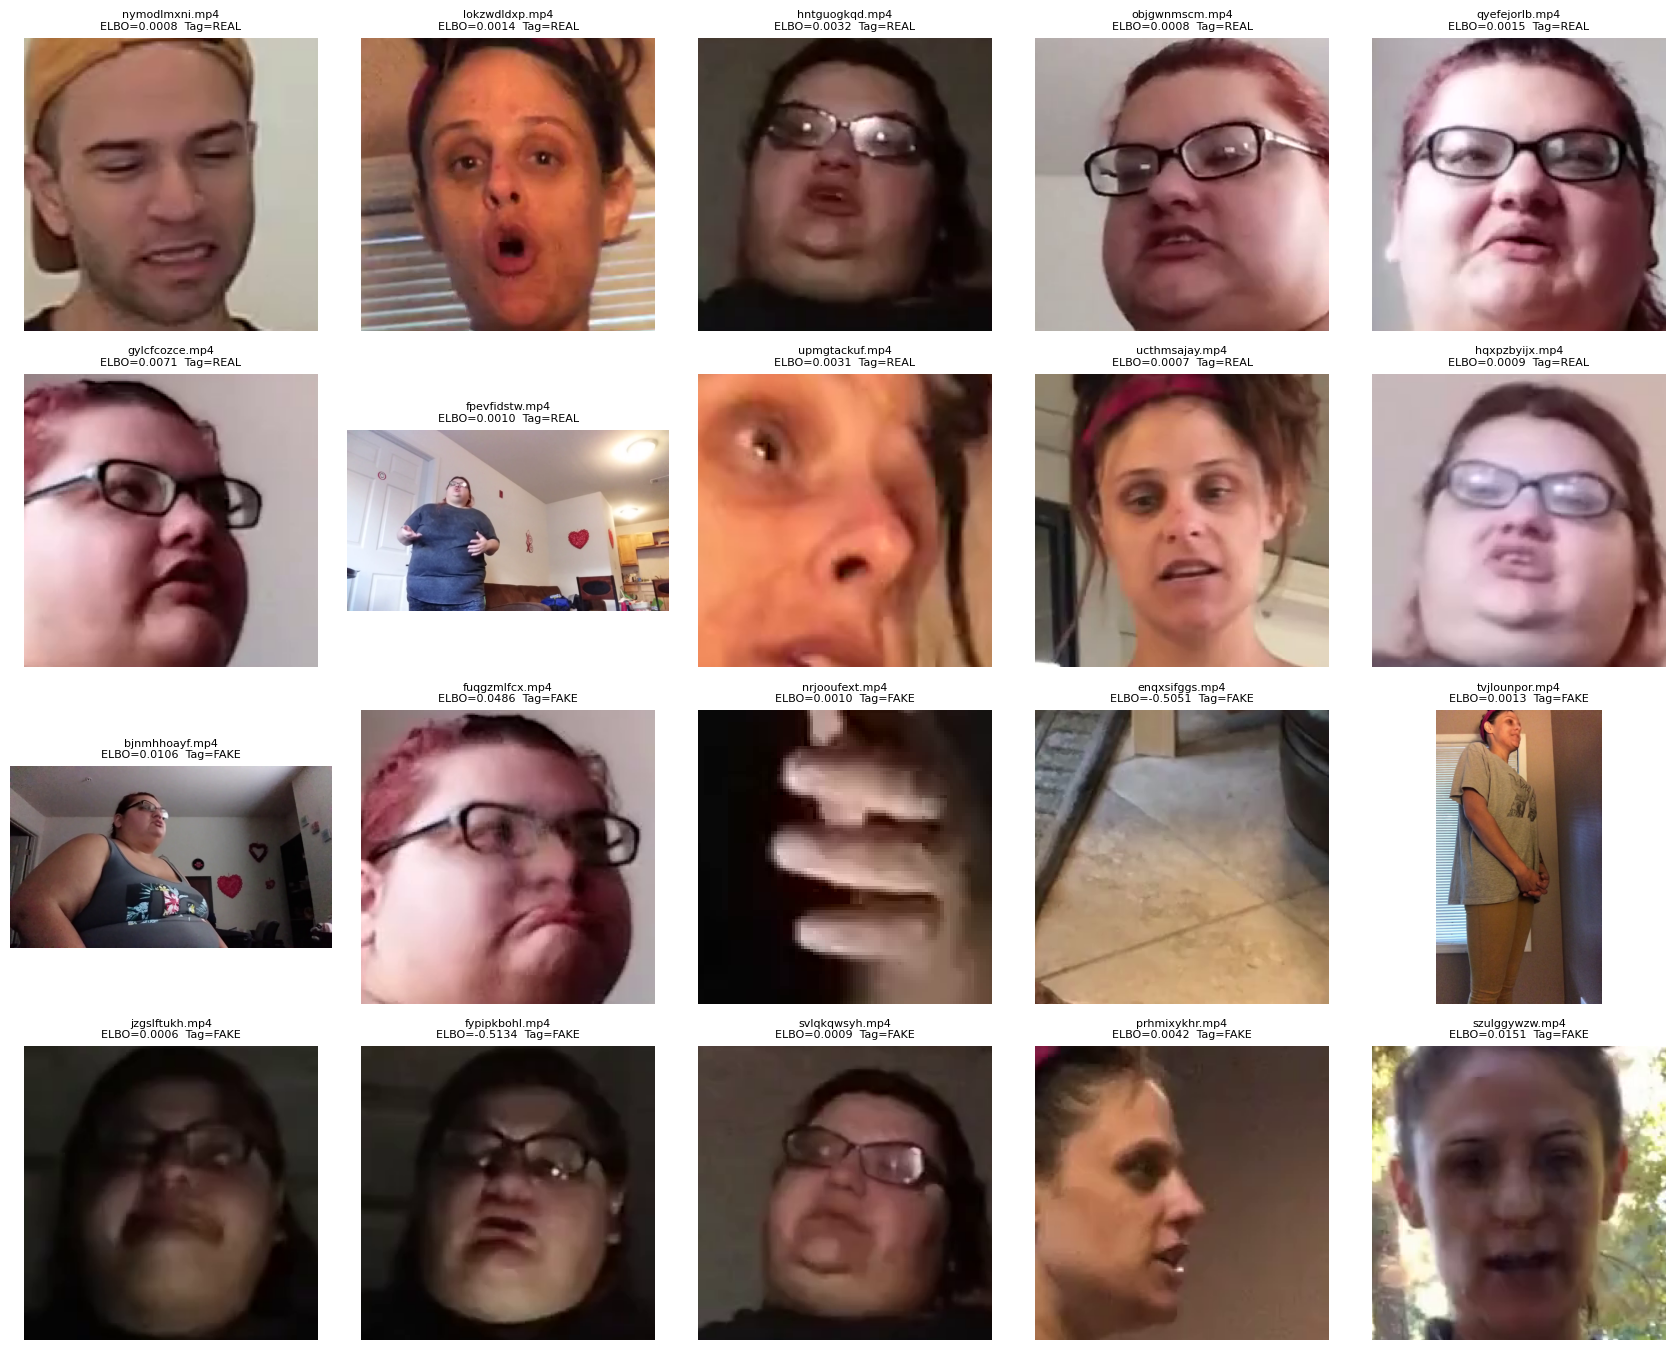

In [63]:
# === Probe REAL vs FAKE en DFDC con ELBO_est + visualización de recorte ===
import os, random, math, cv2, torch, numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

import diff_utils as DU
from train_utils import (
    read_dfdc_metadata,
    default_preprocess,
    sample_uniform_frames,
    face_crop_fn,   # mismo recorte del training
)

# ---- Config ----
ROOT = r"E:\ERIS\Ernesto\dfdc_train_all"
CKPT = r".\checkpoints_dfdc_eps\eps_unet_final.pt"
PARTS = (0, 1)
FRAMES_PER_VIDEO = 8
N_REAL = 10
N_FAKE = 10
IMAGE_SIZE = 128
CHANNELS = 3
T_STEPS = 300
USE_FACE_CROP = True
SAVE_DIR = "./probe_crops"     # se guarda cada recorte aquí
MAKE_COLLAGE = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(0)
os.makedirs(SAVE_DIR, exist_ok=True)

# ---- Modelo + schedule ----
model = DU.TinyUNet(in_ch=CHANNELS, base=32, t_dim=128).to(DEVICE)
state = torch.load(CKPT, map_location=DEVICE)
model.load_state_dict(state["model"])
model.eval()
sched = DU.build_schedule(T=T_STEPS, device=DEVICE)

# ---- Utilidades ----
def list_videos_with_labels(root: str | Path, parts):
    vids = {"REAL": [], "FAKE": []}
    root = Path(root)
    for p in parts:
        part_dir = root / f"dfdc_train_part_{p}"
        if not part_dir.is_dir():
            continue
        meta = read_dfdc_metadata(part_dir)
        for fname, rec in meta.items():
            label = str(rec.get("label", "")).upper()
            if label in vids:
                vpath = part_dir / fname
                if vpath.is_file():
                    vids[label].append(str(vpath))
    return vids

@torch.no_grad()
def elbo_for_video_with_preview(path: str, frames_per_video=8):
    """
    Devuelve:
      - mean_elbo (float) o None
      - preview_crop_rgb (np.ndarray HxWx3, uint8) del primer frame válido usado (ya recortado)
      - preview_idx (int) índice del frame elegido para preview
    """
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        return None, None, None

    idxs = sample_uniform_frames(cap, want=frames_per_video)
    elbos = []
    preview = None
    preview_idx = None

    for j, idx in enumerate(idxs):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if not ok:
            continue

        # aplicar el mismo recorte del training (fallback a center-crop via default_preprocess)
        crop_bgr = frame
        if USE_FACE_CROP:
            try:
                crop_bgr = face_crop_fn(frame)   # BGR
            except Exception:
                pass

        # guardamos el primer recorte válido como preview (en RGB para mostrar)
        if preview is None:
            preview = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
            preview_idx = int(idx)

        # preprocess para el modelo (center-crop + resize + gray + norm)
        x = default_preprocess(
            frame_bgr=crop_bgr,
            out_size=IMAGE_SIZE,
            to_gray=(CHANNELS == 1),
            norm="tanh"
        ).unsqueeze(0).to(DEVICE)

        e = DU.estimate_elbo_mc(model, x, sched).mean().item()
        elbos.append(e)

    cap.release()
    if not elbos:
        return None, None, None

    return float(np.mean(elbos)), preview, preview_idx

# ---- Selección y corrida ----
vids = list_videos_with_labels(ROOT, PARTS)
random.shuffle(vids["REAL"])
random.shuffle(vids["FAKE"])

sel_real = vids["REAL"][:N_REAL]
sel_fake = vids["FAKE"][:N_FAKE]
selection = [(p, "REAL") for p in sel_real] + [(p, "FAKE") for p in sel_fake]

rows = []
thumbs = []  # (img_rgb, title_str, save_path)

for path, tag in selection:
    mean_elbo, preview_rgb, idx = elbo_for_video_with_preview(path, frames_per_video=FRAMES_PER_VIDEO)
    base = os.path.basename(path)

    if mean_elbo is None:
        print(f"(skip) {base} — no se pudo leer.")
        continue

    # guardar preview
    if preview_rgb is not None:
        save_path = os.path.join(SAVE_DIR, f"{base}_frame{idx}_crop.png")
        cv2.imwrite(save_path, cv2.cvtColor(preview_rgb, cv2.COLOR_RGB2BGR))
        title = f"{base}\nELBO={mean_elbo:.4f}  Tag={tag}"
        thumbs.append((preview_rgb, title, save_path))
    else:
        save_path = os.path.join(SAVE_DIR, f"{base}_nocrop.png")
        title = f"{base}\nELBO={mean_elbo:.4f}  Tag={tag}"
        # generamos un placeholder si hiciera falta
        dummy = np.zeros((IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
        cv2.imwrite(save_path, cv2.cvtColor(dummy, cv2.COLOR_RGB2BGR))
        thumbs.append((dummy, title, save_path))

    rows.append((base, tag, mean_elbo))
    print(f"{base:30s}  ELBO_est = {mean_elbo:8.4f}   Tag = \"{tag}\"  (crop -> {save_path})")

# ---- Resumen + umbral ----
if rows:
    real_vals = [e for (_, t, e) in rows if t == "REAL"]
    fake_vals = [e for (_, t, e) in rows if t == "FAKE"]
    if real_vals: print("REAL  mean=%.4f  std=%.4f" % (np.mean(real_vals), np.std(real_vals)))
    if fake_vals: print("FAKE  mean=%.4f  std=%.4f" % (np.mean(fake_vals), np.std(fake_vals)))
    if real_vals and fake_vals:
        thr = 0.5 * (np.mean(real_vals) + np.mean(fake_vals))
        print("Umbral sugerido (promedios):", round(thr, 4))

# ---- Collage opcional ----
if MAKE_COLLAGE and thumbs:
    cols = 5
    rows_fig = math.ceil(len(thumbs) / cols)
    plt.figure(figsize=(3.4 * cols, 3.4 * rows_fig))
    for i, (img, title, _) in enumerate(thumbs, 1):
        ax = plt.subplot(rows_fig, cols, i)
        ax.imshow(img)
        ax.set_title(title, fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    collage_path = os.path.join(SAVE_DIR, "collage_probe.png")
    plt.savefig(collage_path, dpi=150)
    print(f"Collage guardado en: {collage_path}")
